In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from scipy import stats
from aqs import features as F, plots as P
from aqs.config import CITIES, HEADLINE_TERMS, INTERIM, WHO_24H_GUIDELINE

P.use_theme()
long, pm25 = F.load_long(), F.load_pm25()
print(f"{len(pm25)} city-weeks of PM2.5, {long.groupby(['city', 'geo_level', 'term']).ngroups} search series")

503 city-weeks of PM2.5, 62 search series


In [2]:
sel = pd.read_csv(INTERIM / "sensor_selection.csv")
quality = sel.groupby("city").agg(candidate_sensors=("sensor_id", "size"),
                                  kept=("decision", lambda d: (d == "kept").sum()))
quality["weeks_with_data"] = pm25.groupby("city").size()
quality["weeks_in_window"] = 156
quality["coverage_%"] = (quality["weeks_with_data"] / 156 * 100).round(0).astype(int)
quality["median_PM2.5"] = pm25.groupby("city")["pm25_mean"].median().round(1)
quality.reindex(list(CITIES))

,candidate_sensors,kept,weeks_with_data,weeks_in_window,coverage_%,median_PM2.5
city,,,,,,
bangkok,182,64,150,156,96,22.1
krakow,5,2,134,156,86,14.9
melbourne,25,8,96,156,62,5.6
lahore,2,1,123,156,79,92.4


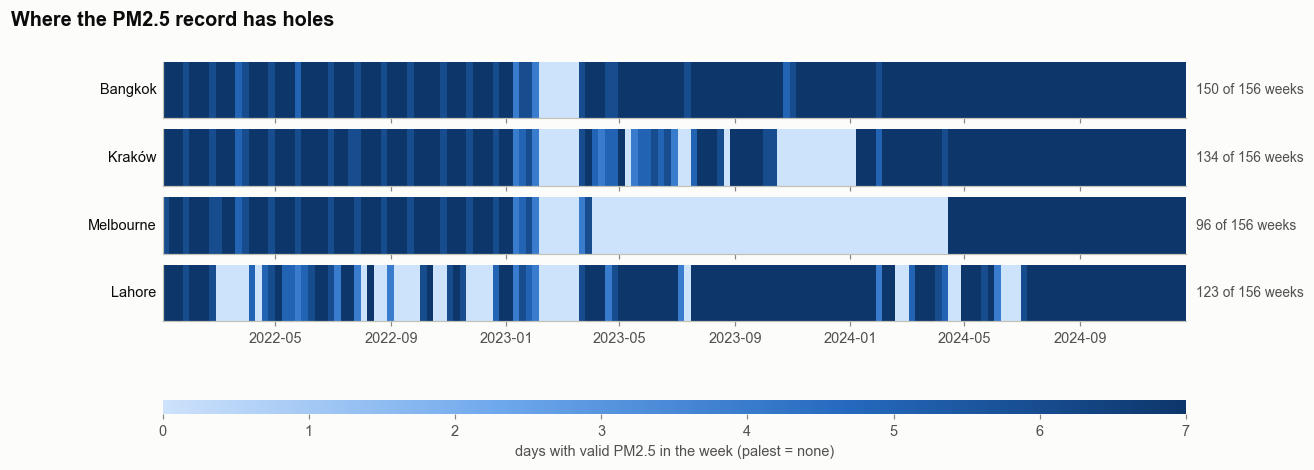

In [3]:
P.coverage_strips(pm25);

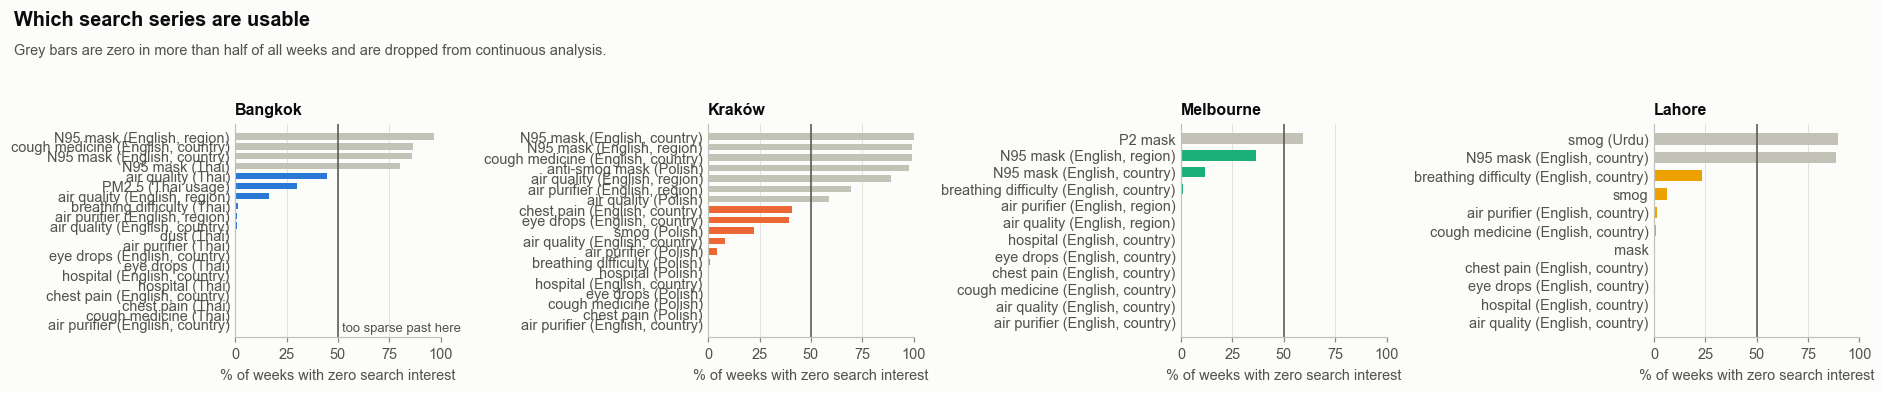

In [4]:
P.zero_inflation(long);

In [5]:
pd.DataFrame({c: {r: F.term_label(c, t) for r, t in HEADLINE_TERMS[c].items()} for c in CITIES}).T

,awareness,protection,health
bangkok,dust (Thai),air purifier (Thai),breathing difficulty (Thai)
krakow,smog (Polish),air purifier (Polish),breathing difficulty (Polish)
melbourne,"air quality (English, region)","air purifier (English, region)","breathing difficulty (English, country)"
lahore,smog,"air purifier (English, country)","breathing difficulty (English, country)"


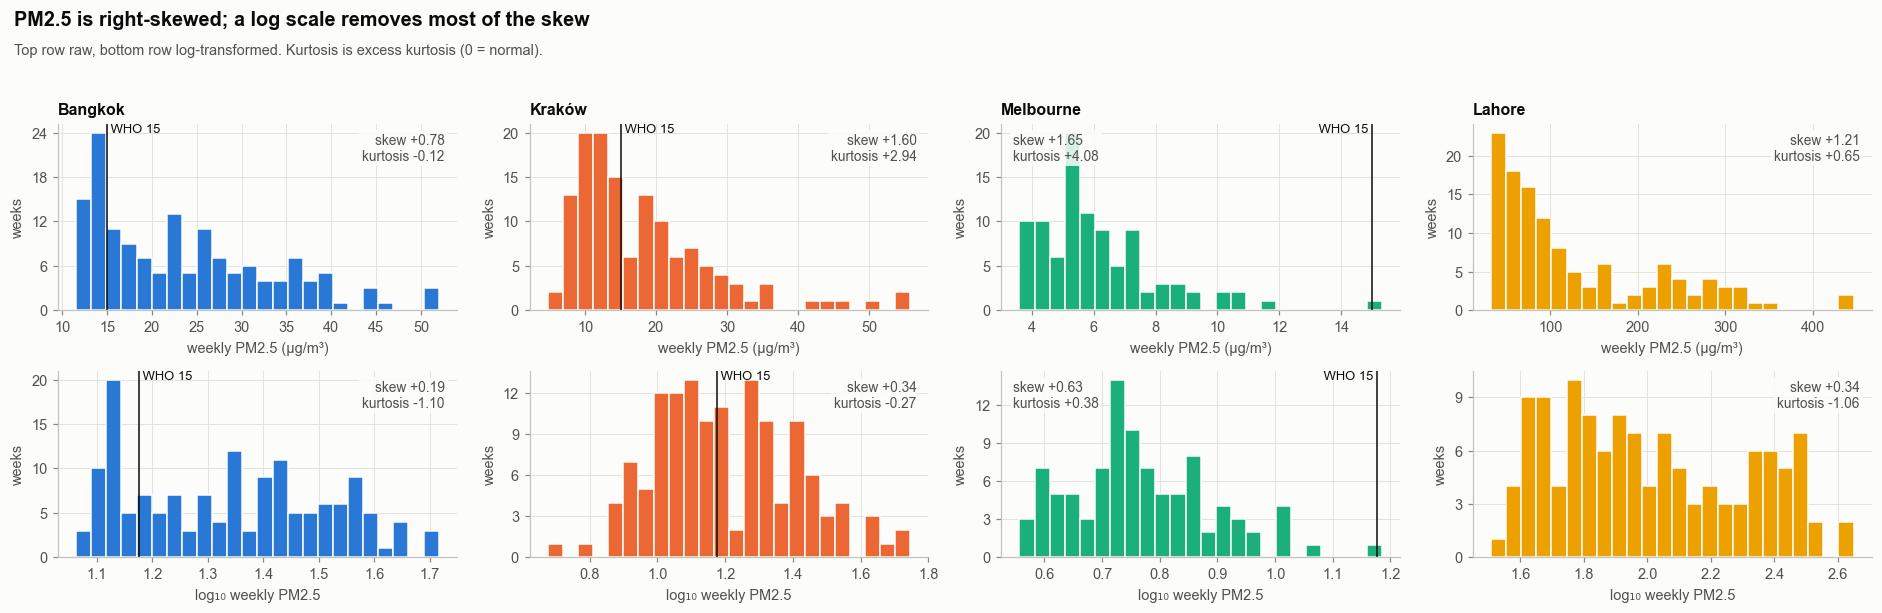

In [6]:
P.distributions(pm25);

In [7]:
shape = pm25.groupby("city")["pm25_mean"].agg(
    mean="mean", median="median", std="std",
    iqr=lambda x: x.quantile(.75) - x.quantile(.25),
    skew=stats.skew, kurtosis=stats.kurtosis,
    pct_above_WHO=lambda x: (x > WHO_24H_GUIDELINE).mean() * 100).round(2)
shape.reindex(list(CITIES))

,mean,median,std,iqr,skew,kurtosis,pct_above_WHO
city,,,,,,,
bangkok,23.72,22.05,9.76,15.24,0.78,-0.12,74.00
krakow,18.02,14.92,9.74,10.89,1.60,2.94,50.00
melbourne,6.15,5.60,1.98,2.11,1.65,4.08,1.04
lahore,129.73,92.41,94.90,126.25,1.21,0.65,100.00


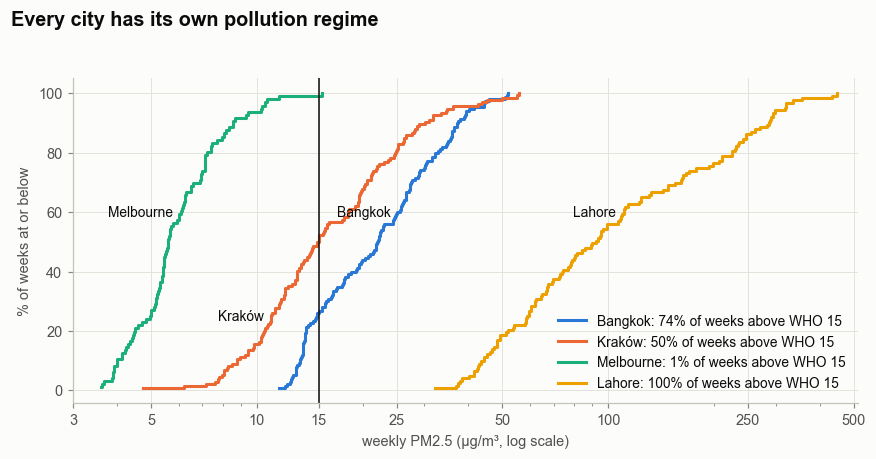

In [8]:
P.ecdf(pm25);

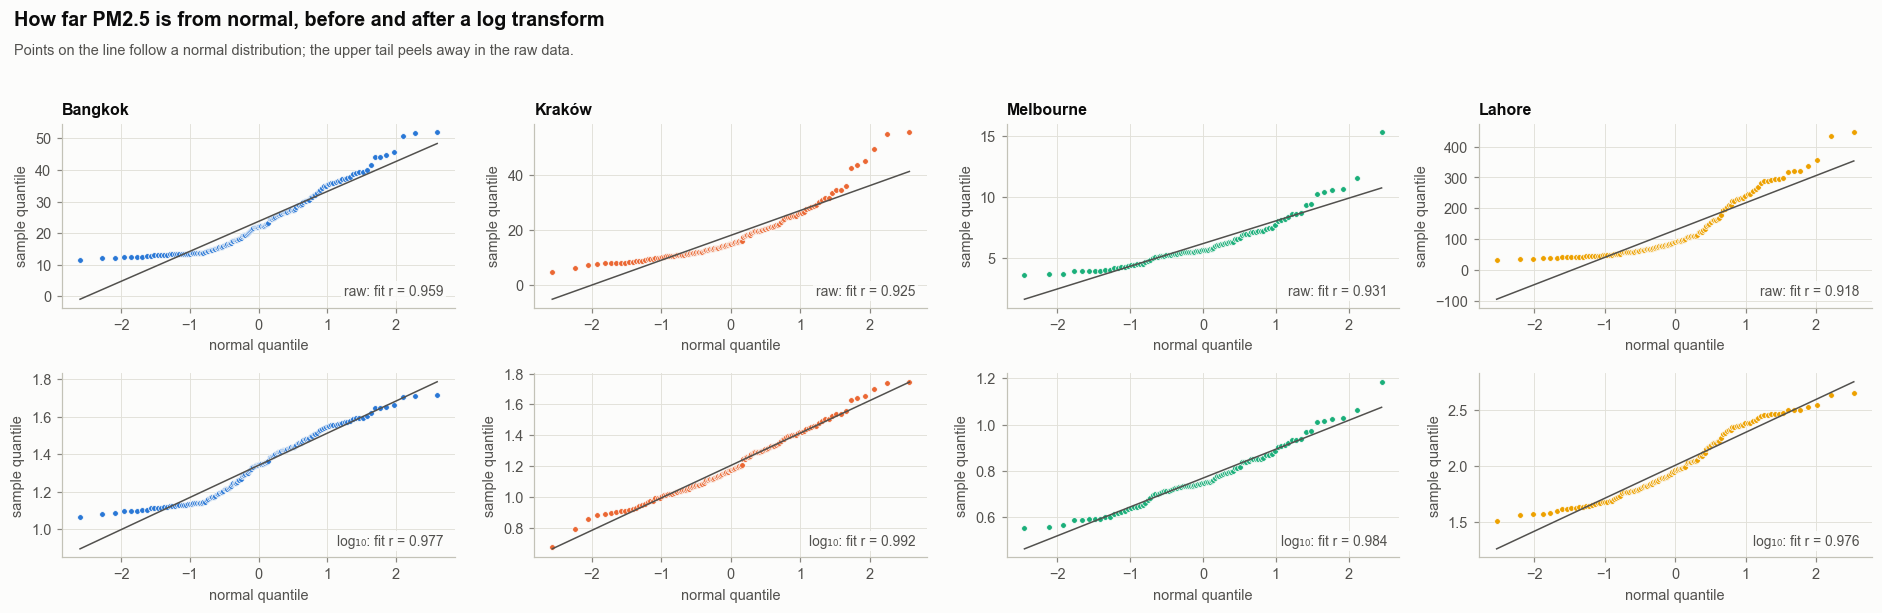

In [9]:
P.qq_plots(pm25);

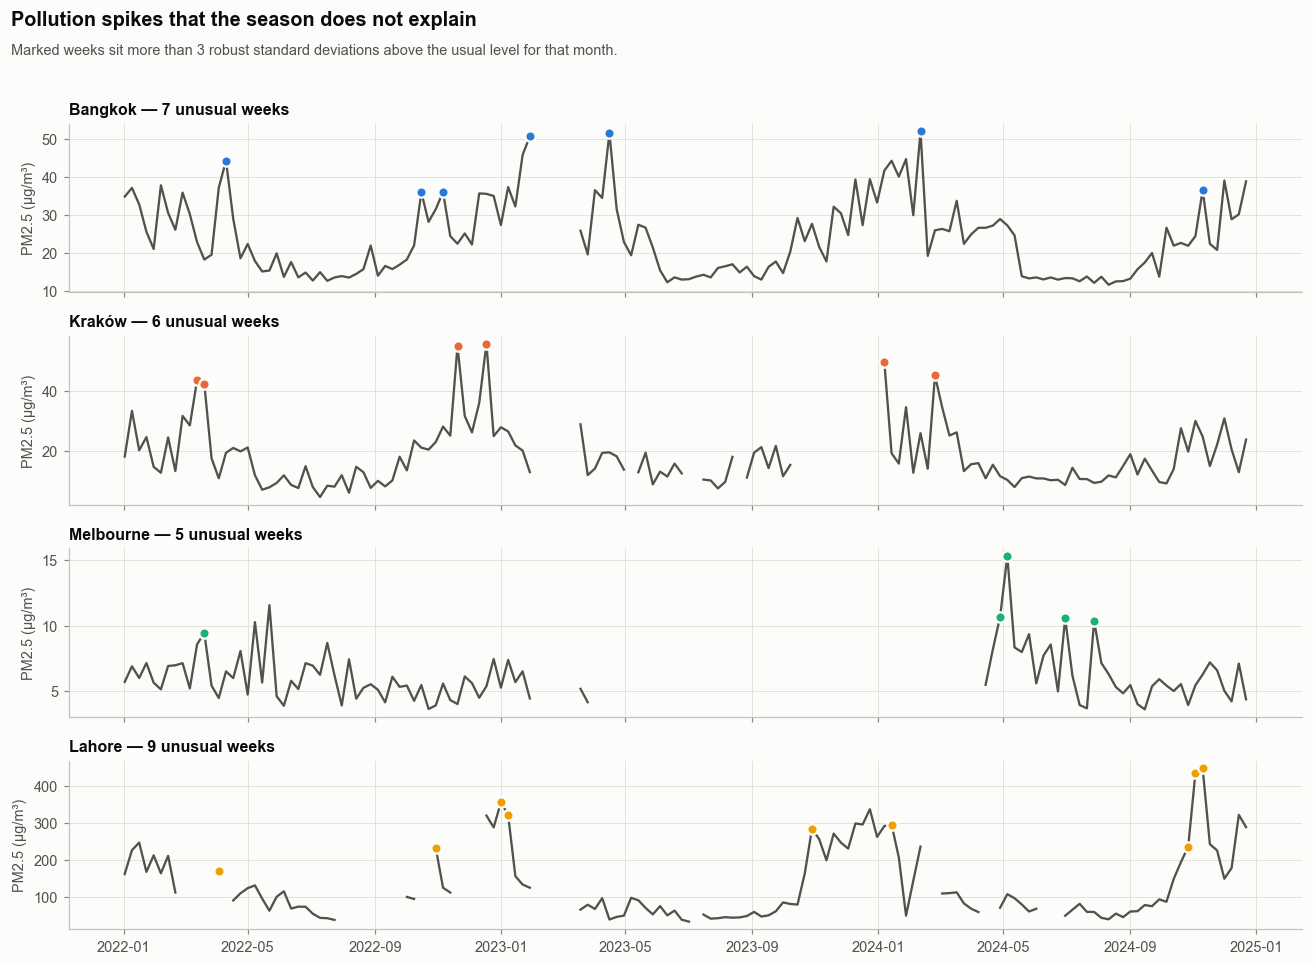

In [10]:
P.outlier_timeline(pm25);

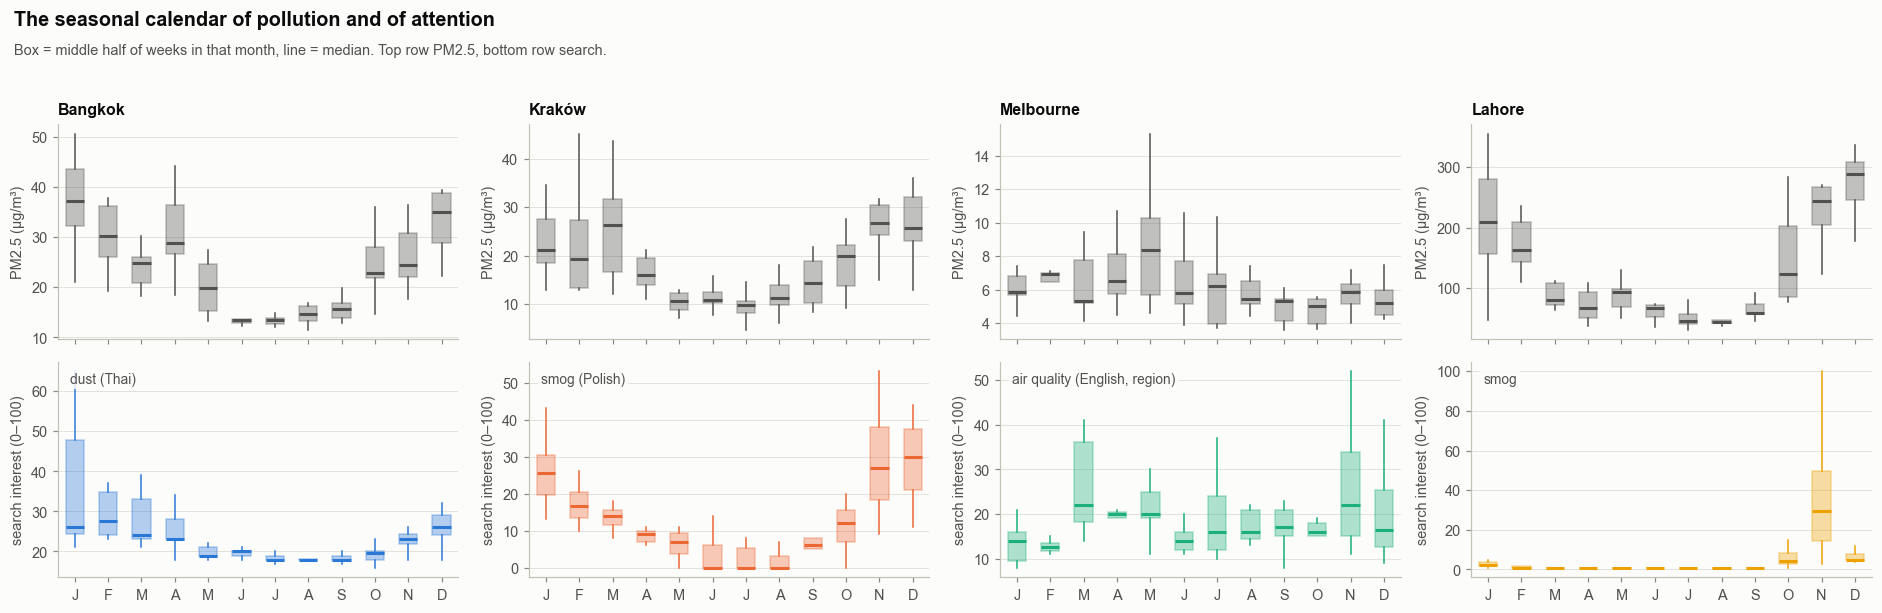

In [11]:
P.seasonal_profile(long);

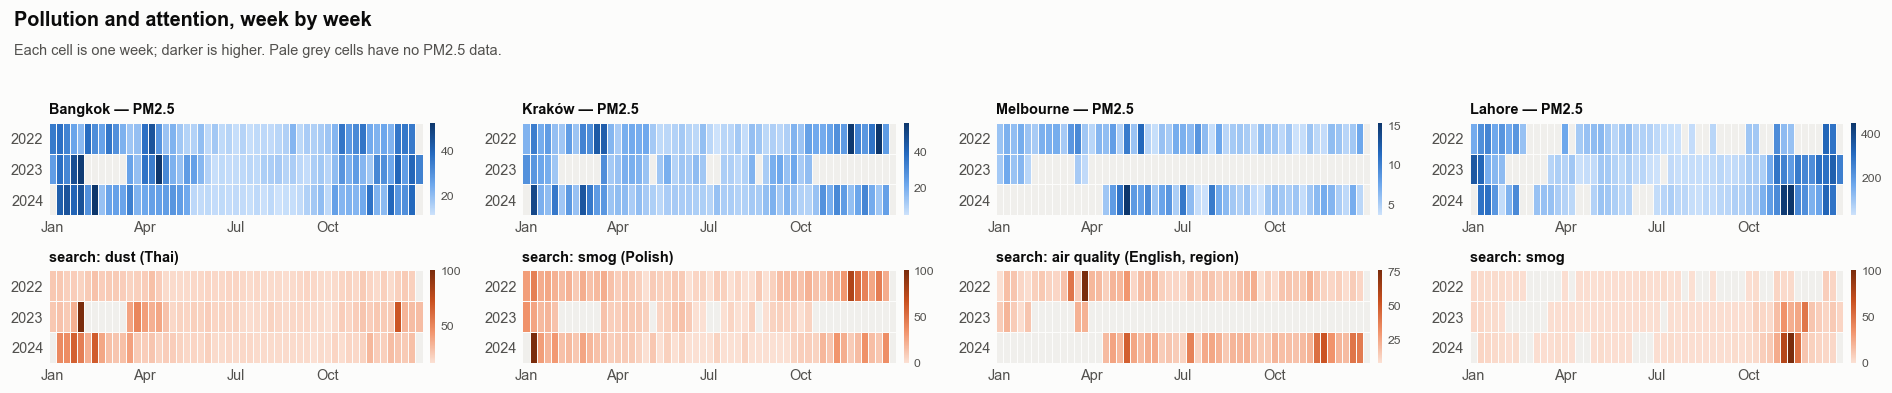

In [12]:
P.calendar_heatmaps(long);

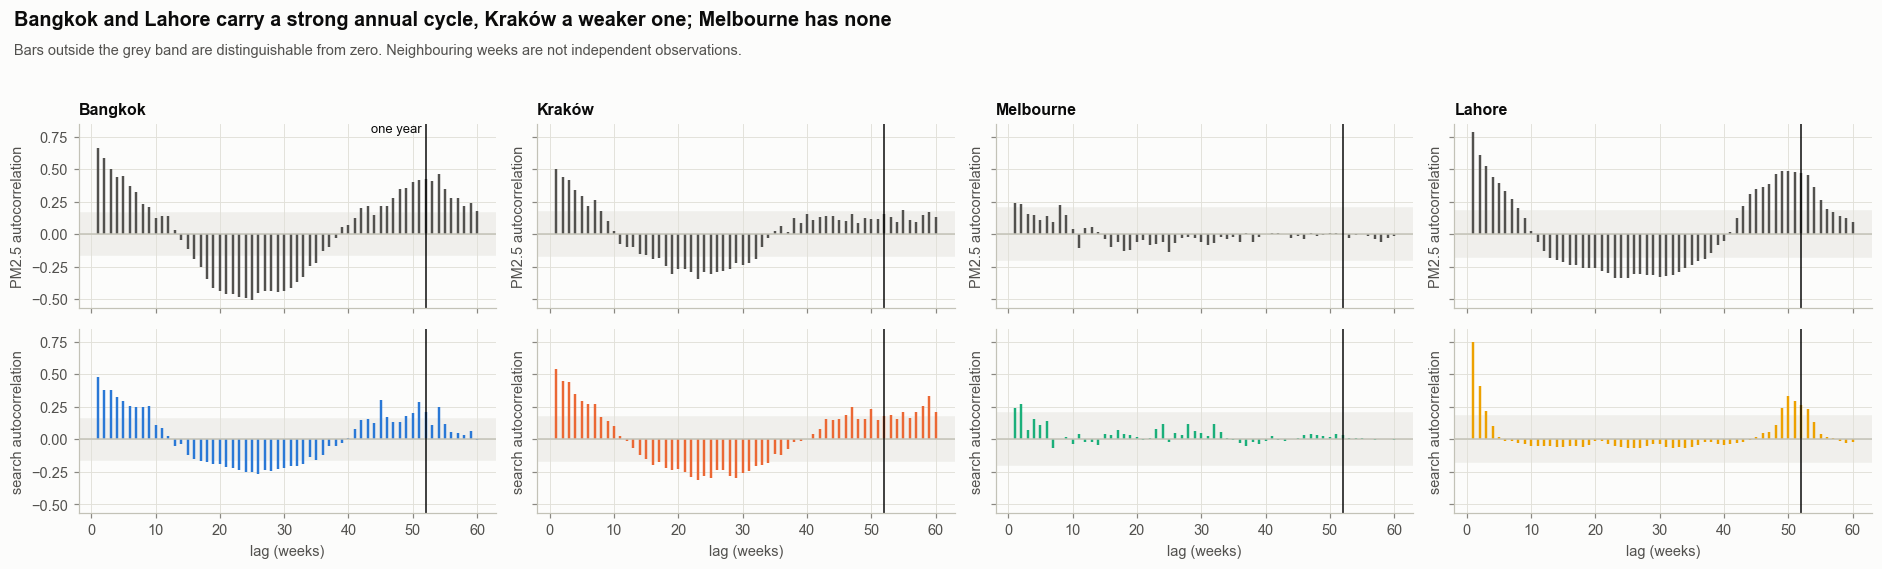

In [13]:
P.autocorrelation(long);

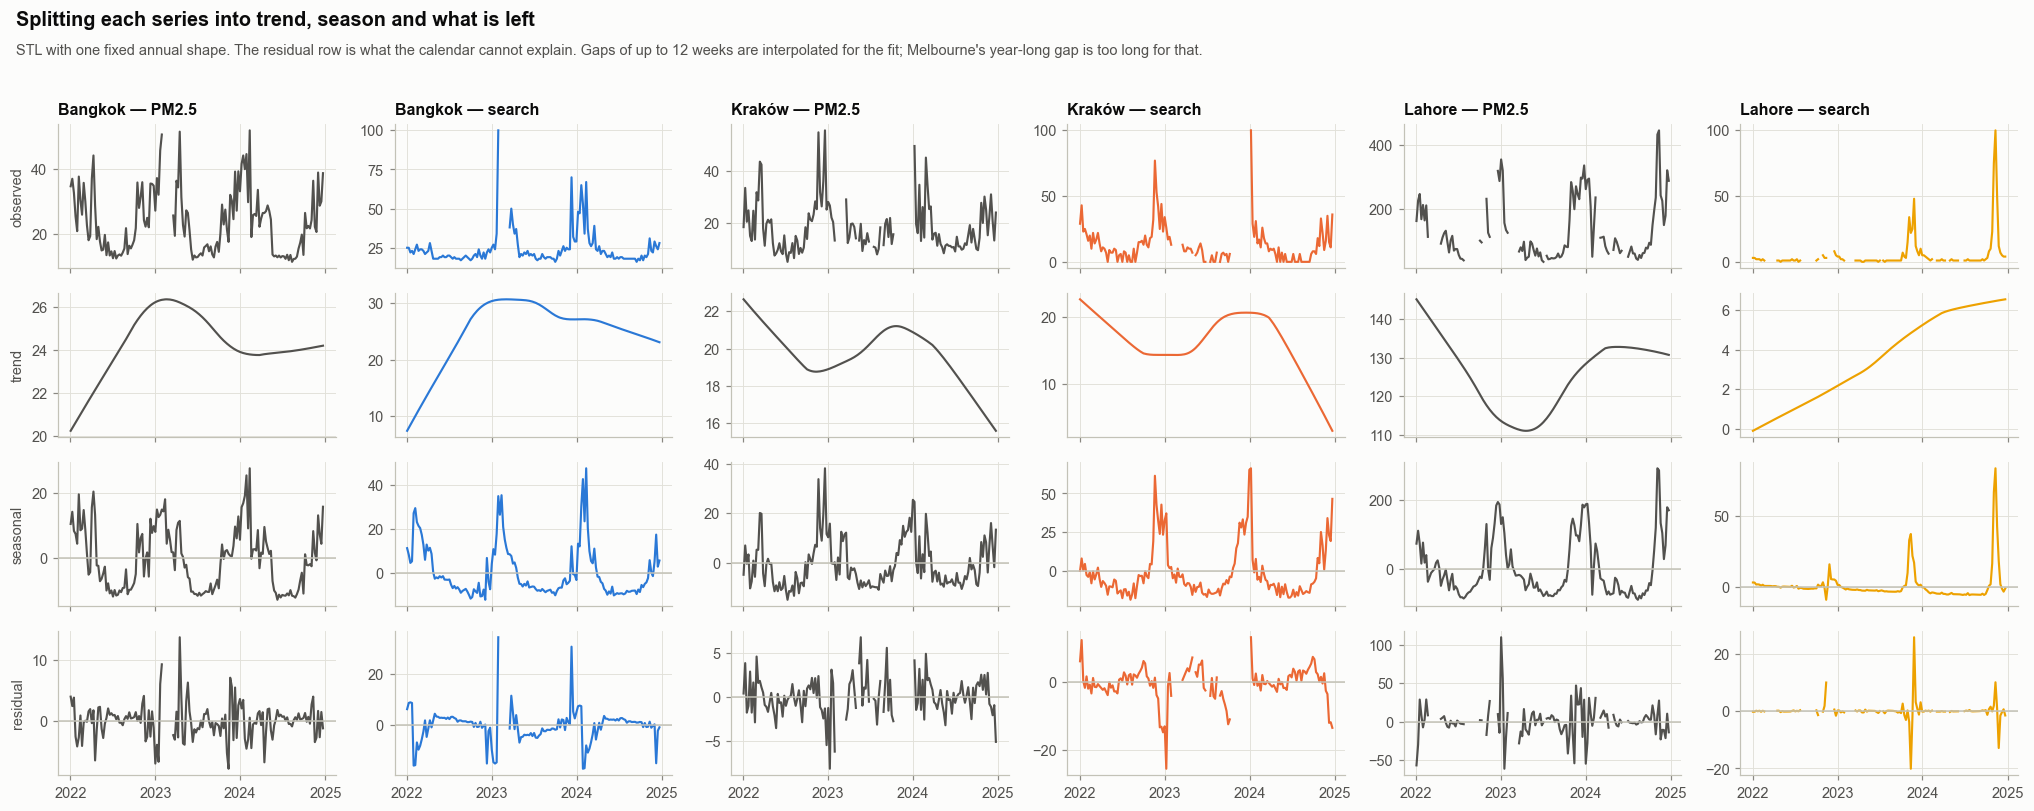

In [14]:
P.stl_decomposition(long);

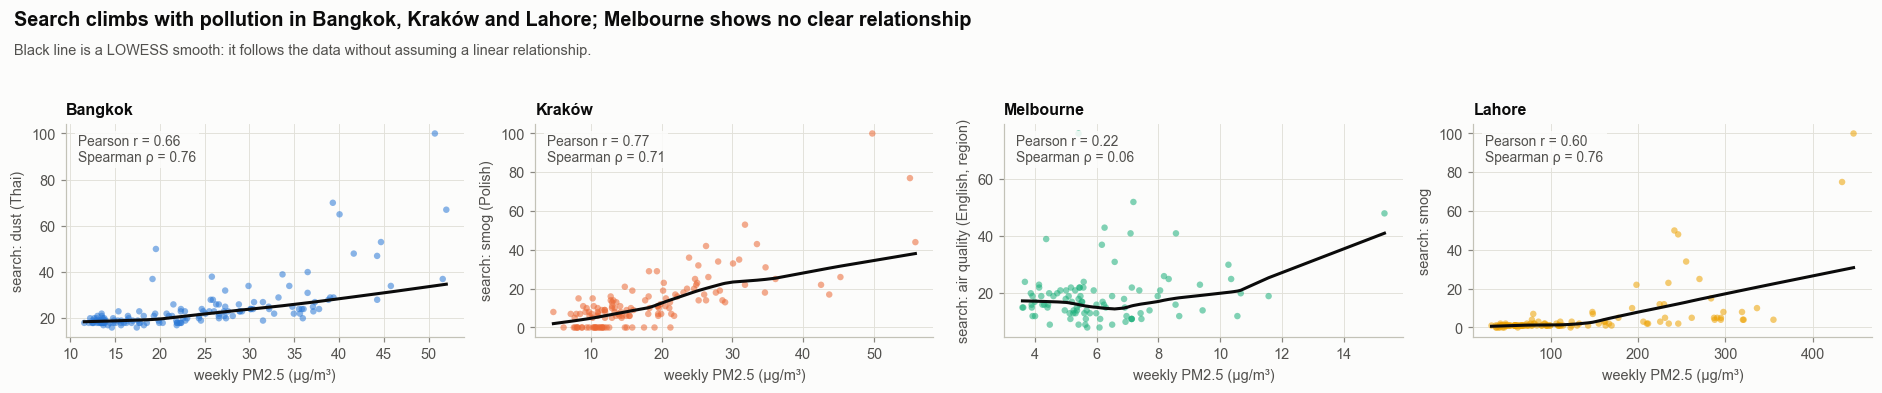

In [15]:
P.scatter_lowess(long);

,city,label,pearson,spearman
0,bangkok,"air purifier (English, country)",0.58,0.73
1,bangkok,"air quality (English, country)",0.65,0.77
2,bangkok,breathing difficulty (Thai),0.05,-0.03
3,bangkok,"chest pain (English, country)",-0.07,-0.08
4,bangkok,chest pain (Thai),0.23,0.21
5,bangkok,cough medicine (Thai),0.08,0.09
6,bangkok,"eye drops (English, country)",-0.08,-0.12
7,bangkok,eye drops (Thai),0.05,0.05
8,bangkok,"hospital (English, country)",-0.01,0.01
9,bangkok,hospital (Thai),-0.02,-0.20


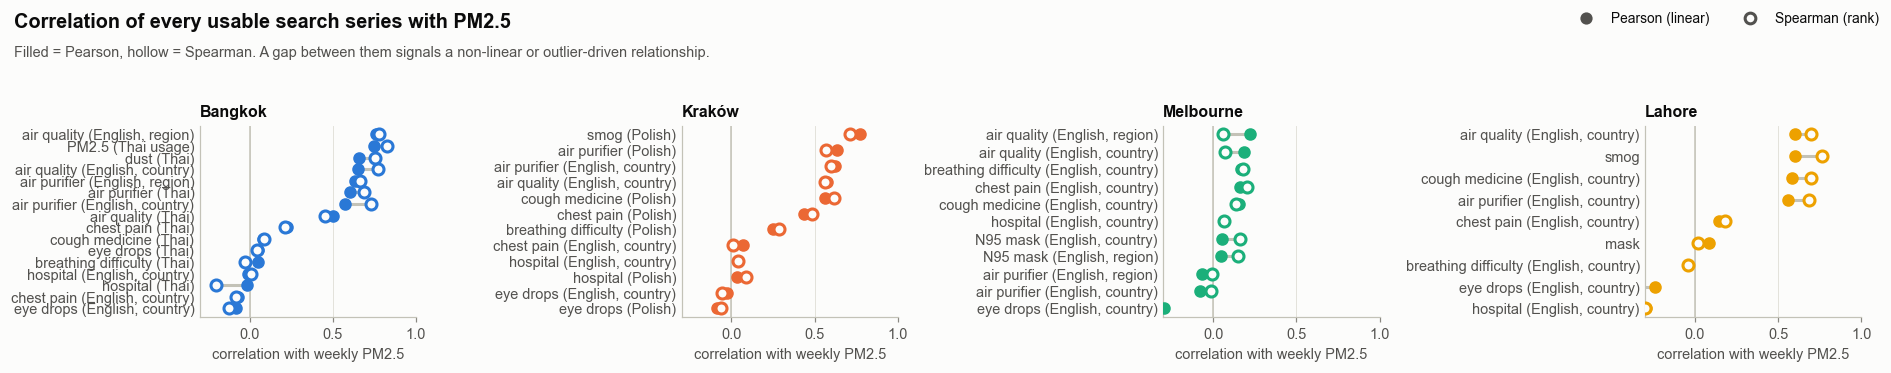

In [16]:
fig, corr = P.pearson_vs_spearman(long)
corr.round(2)

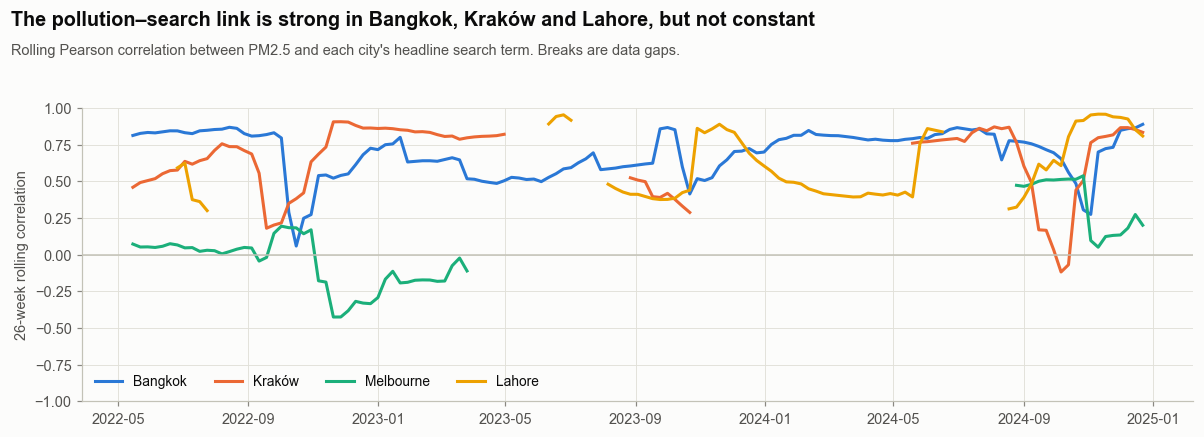

In [17]:
P.rolling_correlations(long);

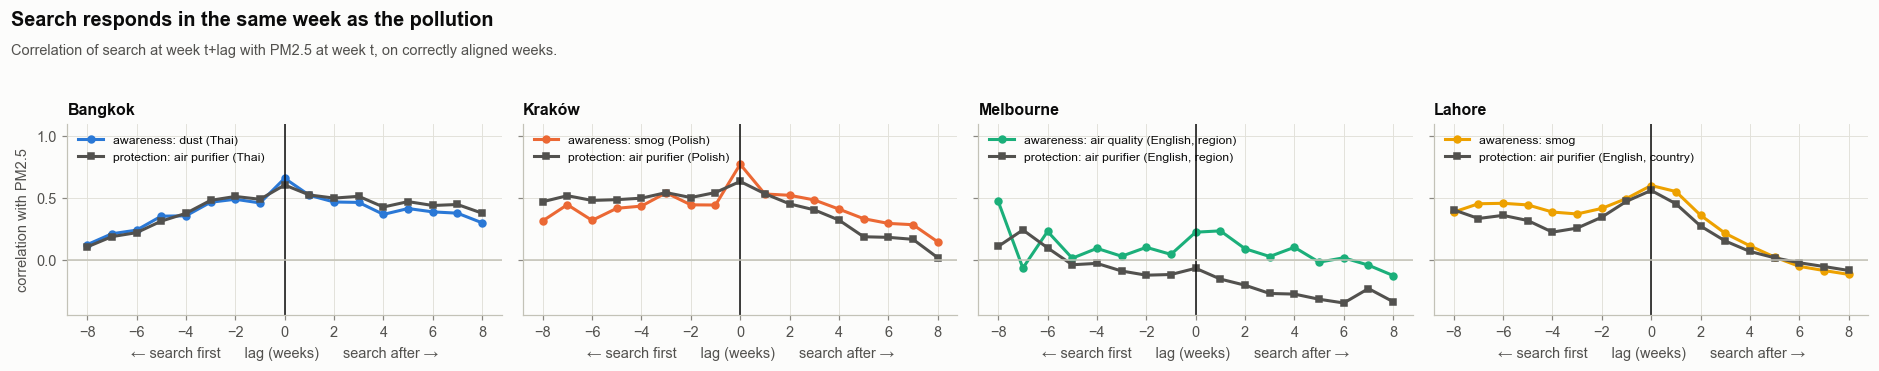

In [18]:
P.lag_profiles(long);

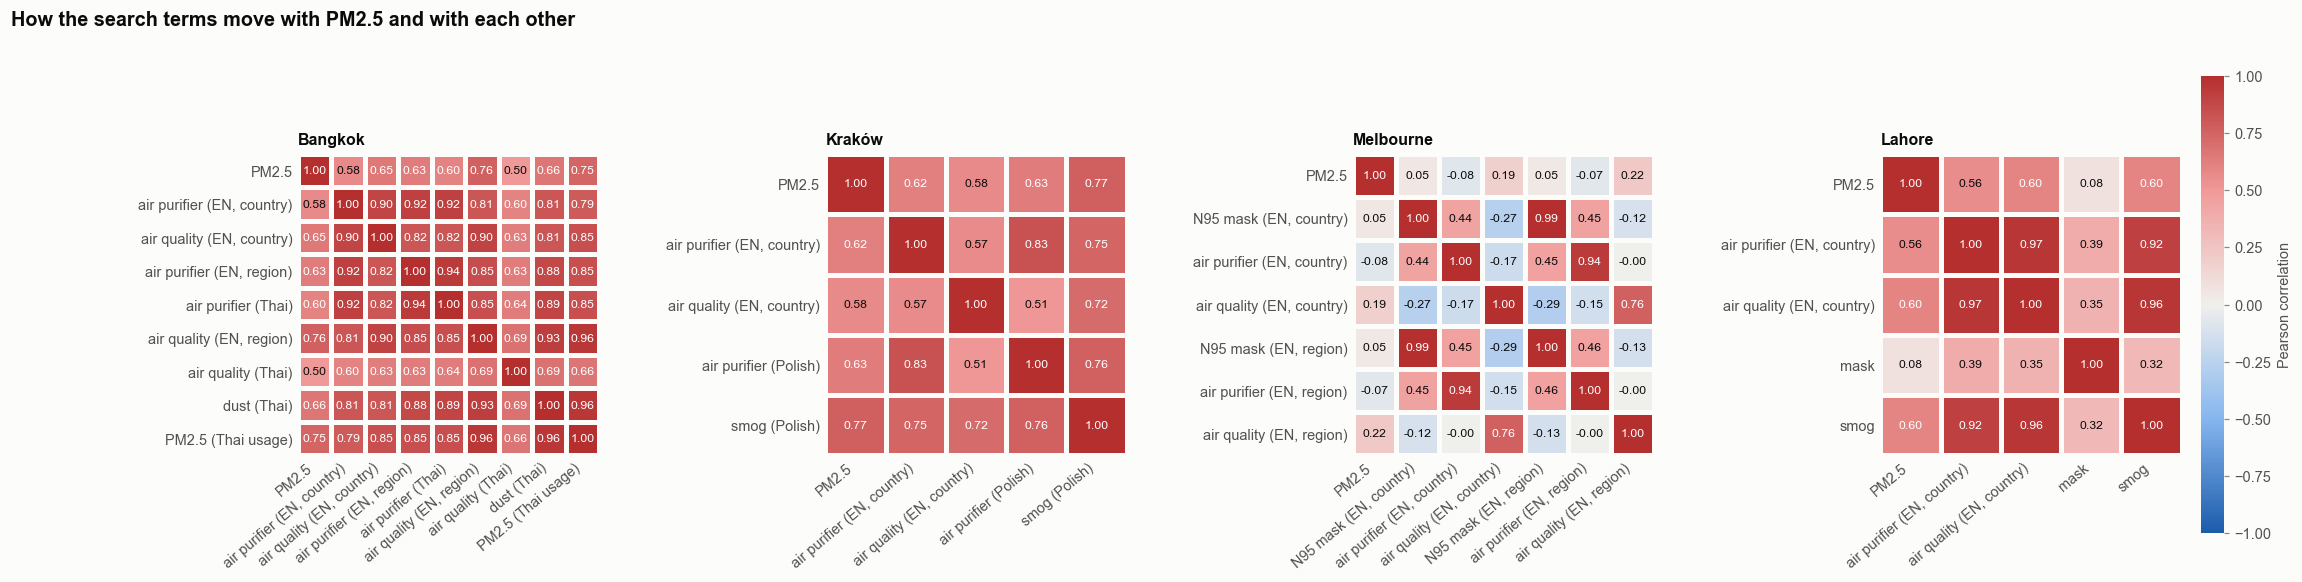

In [19]:
P.correlation_heatmaps(long);

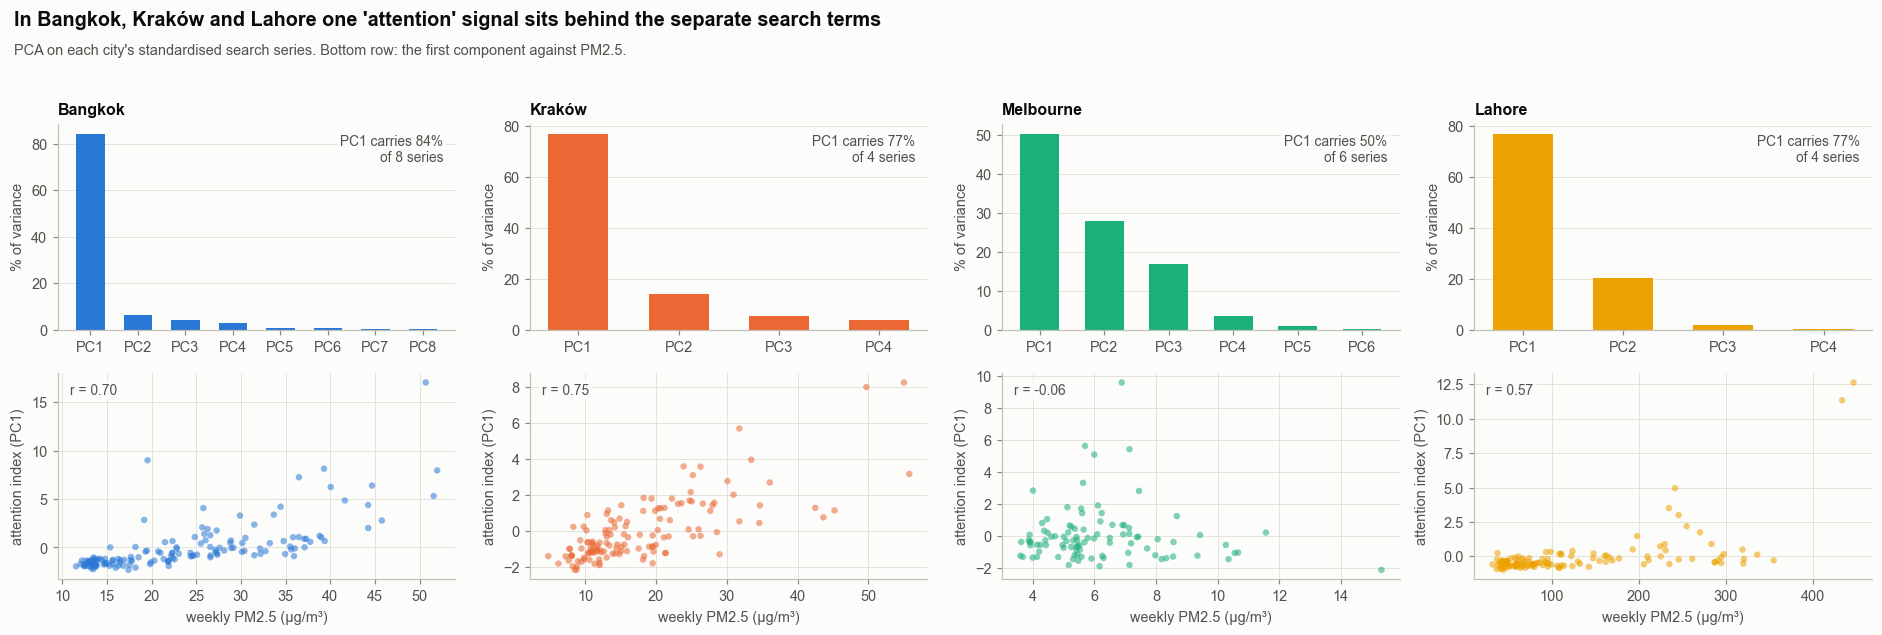

In [20]:
P.pca_summary(long);

In [21]:
pd.DataFrame({c: pd.Series(F.attention_index(long, c)[1]).rename(lambda k: f"PC{k + 1}") for c in CITIES}).T.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
bangkok,0.84,0.06,0.04,0.03,0.01,0.01,0.0,0.0
krakow,0.77,0.14,0.05,0.04,NaN,NaN,NaN,NaN
melbourne,0.50,0.28,0.17,0.04,0.01,0.00,NaN,NaN
lahore,0.77,0.21,0.02,0.00,NaN,NaN,NaN,NaN


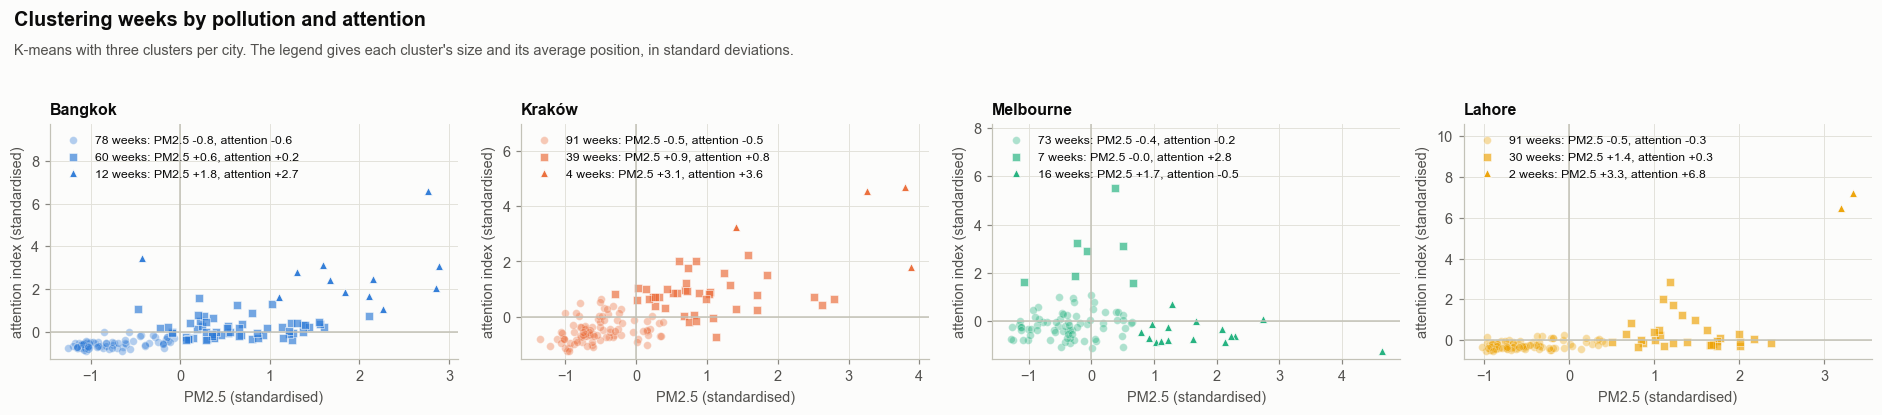

In [22]:
fig, clusters = P.regimes(long)